# 04 · Modelado: pronóstico de la demanda

**Entrada:** `data/processed/consumo_horario.parquet` · **Funciones:** `src/features.py` y `src/modeling.py`
**Parámetros:** `src/config.py` (`HORIZONTE_HORAS`, `REZAGOS_HORAS`, `VENTANAS_HORAS`, `FECHA_CORTE`, `SEMILLA`)

**Diseño del experimento**

| Elemento | Decisión |
|---|---|
| Objetivo | Consumo horario (`MW`) de una región |
| Horizonte | 24 horas: para predecir la hora *t* solo se usa información hasta *t − 24* |
| División | Cronológica: entrenamiento antes de `FECHA_CORTE`, prueba desde esa fecha |
| Modelo base | El consumo de ayer a la misma hora |
| Modelo | XGBoost con variables de calendario, rezagos y medias móviles |
| Métricas | MAE y RMSE (en MW) y MAPE (en %) |

**Contenido**
1. Configuración y carga
2. Variables
3. División en entrenamiento y prueba
4. Modelo base
5. XGBoost
6. Evaluación
7. Análisis de errores
8. Resumen y limitaciones

## 1. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import PROCESSED_DIR, HORIZONTE_HORAS, REZAGOS_HORAS, VENTANAS_HORAS, FECHA_CORTE
from src.features import agregar_variables_temporales, agregar_rezagos, agregar_medias_moviles
from src.modeling import (
    seleccionar_variables,
    dividir_train_test,
    construir_X_y,
    pronostico_base,
    entrenar_xgboost,
    predecir,
    comparar_modelos,
    importancia_variables,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

REGION = 'PJME'    # región a pronosticar

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
df = df[df['region'] == REGION]

print(f"{REGION}: {len(df):,} filas · {df['Datetime'].min():%Y-%m-%d} → {df['Datetime'].max():%Y-%m-%d}")
print(f"Horizonte: {HORIZONTE_HORAS} h · rezagos: {REZAGOS_HORAS} · ventanas: {VENTANAS_HORAS} · corte: {FECHA_CORTE}")

PJME: 145,392 filas · 2002-01-01 → 2018-08-03
Horizonte: 24 h · rezagos: [24, 48, 168] · ventanas: [24, 168] · corte: 2017-01-01


## 2. Variables

- **Calendario:** hora, día de la semana, mes, fin de semana y festivo. Se conocen de antemano.
- **Rezagos:** consumo de hace 24, 48 y 168 horas.
- **Medias móviles:** promedio de las 24 y 168 horas previas, desplazado 24 horas.

Todas las variables de historia respetan el horizonte: ninguna usa información posterior a *t − 24*.

In [3]:
df = agregar_variables_temporales(df)
df = agregar_rezagos(df)
df = agregar_medias_moviles(df)

variables = seleccionar_variables(df)
print("Variables del modelo:", variables)
print(f"Rezago mínimo: {min(REZAGOS_HORAS)} h (horizonte: {HORIZONTE_HORAS} h)")
df[['Datetime', 'MW'] + variables].head()

Variables del modelo: ['hora', 'dia_semana', 'mes', 'es_fin_de_semana', 'es_festivo', 'MW_lag_24', 'MW_lag_48', 'MW_lag_168', 'MW_media_24h', 'MW_media_168h']
Rezago mínimo: 24 h (horizonte: 24 h)


,Datetime,MW,hora,dia_semana,mes,es_fin_de_semana,es_festivo,MW_lag_24,MW_lag_48,MW_lag_168,MW_media_24h,MW_media_168h
0,2002-01-01 01:00:00,30393.0,1,1,1,False,True,NaN,NaN,NaN,NaN,NaN
1,2002-01-01 02:00:00,29265.0,2,1,1,False,True,NaN,NaN,NaN,NaN,NaN
2,2002-01-01 03:00:00,28357.0,3,1,1,False,True,NaN,NaN,NaN,NaN,NaN
3,2002-01-01 04:00:00,27899.0,4,1,1,False,True,NaN,NaN,NaN,NaN,NaN
4,2002-01-01 05:00:00,28057.0,5,1,1,False,True,NaN,NaN,NaN,NaN,NaN


## 3. División en entrenamiento y prueba

La división es por fecha, nunca al azar: el modelo se entrena con el pasado y se evalúa con un futuro que no ha visto. Los rezagos se calcularon antes de dividir, así que las primeras horas de la prueba usan el final del entrenamiento (información que sí existiría en la práctica).

In [4]:
train, test = dividir_train_test(df)

X_train, y_train = construir_X_y(train)
X_test, y_test = construir_X_y(test)

print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")

Entrenamiento: 131,495 filas (2002-01-01 → 2016-12-31)
Prueba:        13,897 filas (2017-01-01 → 2018-08-03)
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
X_train: (131304, 10) · X_test: (13897, 10)


## 4. Modelo base

Referencias sencillas que cualquier modelo debe superar: el consumo de ayer a la misma hora (24 h) y el de la semana anterior (168 h).

In [5]:
base_24h = pronostico_base(test, rezago=24).loc[X_test.index]
base_168h = pronostico_base(test, rezago=168).loc[X_test.index]

comparar_modelos(y_test, {'Base 24 h': base_24h, 'Base 168 h': base_168h}).round(2)

,MAE,RMSE,MAPE_%
Base 24 h,2300.08,3134.18,7.32
Base 168 h,3511.18,4793.98,10.99


## 5. XGBoost

Se entrena con los valores por defecto de `entrenar_xgboost` (500 árboles, tasa de aprendizaje 0.05, profundidad 6). Los parámetros se pueden sobrescribir al llamar a la función.

In [6]:
modelo = entrenar_xgboost(X_train, y_train)
pred_xgb = predecir(modelo, X_test)

pred_xgb.head()

131495    29365.078125
131496    28207.972656
131497    27957.007812
131498    27294.669922
131499    26845.603516
Name: prediccion, dtype: float32

## 6. Evaluación

In [7]:
metricas = comparar_modelos(y_test, {
    'Base 24 h': base_24h,
    'Base 168 h': base_168h,
    'XGBoost': pred_xgb,
})
metricas.round(2)

,MAE,RMSE,MAPE_%
Base 24 h,2300.08,3134.18,7.32
Base 168 h,3511.18,4793.98,10.99
XGBoost,1862.27,2513.11,5.89


In [8]:
mejora = (1 - metricas.loc['XGBoost', 'MAE'] / metricas.loc['Base 24 h', 'MAE']) * 100
print(f"XGBoost reduce el MAE un {mejora:.1f} % respecto al modelo base de 24 h")

XGBoost reduce el MAE un 19.0 % respecto al modelo base de 24 h


### Real frente a pronóstico

Ventana de dos semanas alrededor del mayor pico de consumo del periodo de prueba.

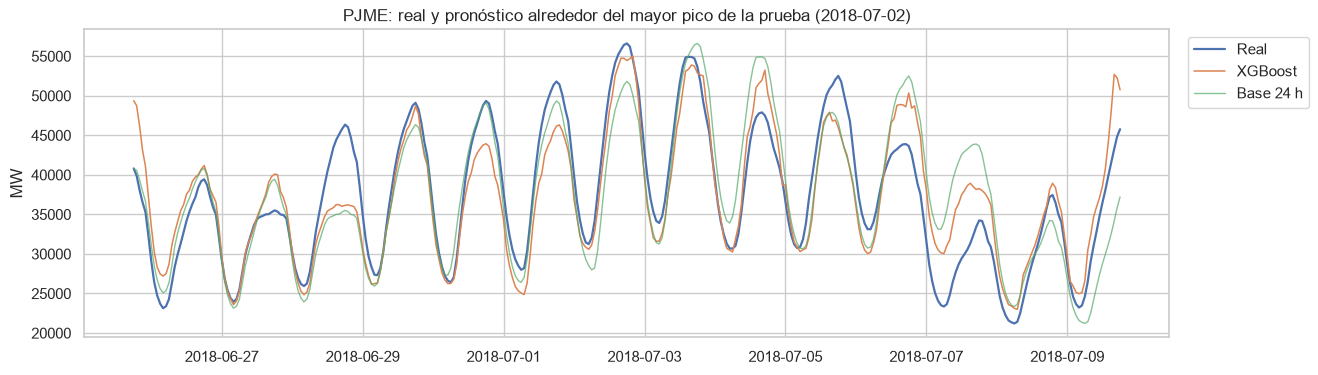

In [9]:
resultados = (
    test.loc[X_test.index, ['Datetime', 'MW', 'hora', 'mes', 'es_festivo', 'es_fin_de_semana']]
    .assign(xgboost=pred_xgb, base_24h=base_24h)
)
resultados['error_xgboost'] = (resultados['xgboost'] - resultados['MW']).abs()
resultados['error_base_24h'] = (resultados['base_24h'] - resultados['MW']).abs()

fecha_pico = resultados.loc[resultados['MW'].idxmax(), 'Datetime']
ventana = resultados[resultados['Datetime'].between(
    fecha_pico - pd.Timedelta(days=7), fecha_pico + pd.Timedelta(days=7))]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ventana['Datetime'], ventana['MW'], label='Real', linewidth=1.6)
ax.plot(ventana['Datetime'], ventana['xgboost'], label='XGBoost', linewidth=1.1)
ax.plot(ventana['Datetime'], ventana['base_24h'], label='Base 24 h', linewidth=1, alpha=0.7)
ax.set_title(f'{REGION}: real y pronóstico alrededor del mayor pico de la prueba ({fecha_pico:%Y-%m-%d})')
ax.set_ylabel('MW')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

## 7. Análisis de errores

Error absoluto medio (MAE, en MW) del modelo base y de XGBoost según la hora, el mes y el tipo de día.

### 7.1 Por hora del día

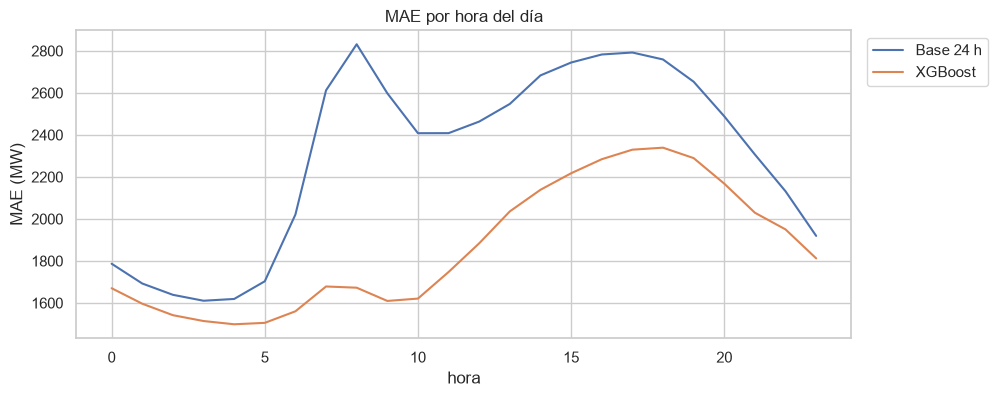

In [10]:
mae_hora = resultados.groupby('hora')[['error_base_24h', 'error_xgboost']].mean()
mae_hora.columns = ['Base 24 h', 'XGBoost']

ax = mae_hora.plot(figsize=(10, 4), title='MAE por hora del día')
ax.set_ylabel('MAE (MW)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### 7.2 Por mes

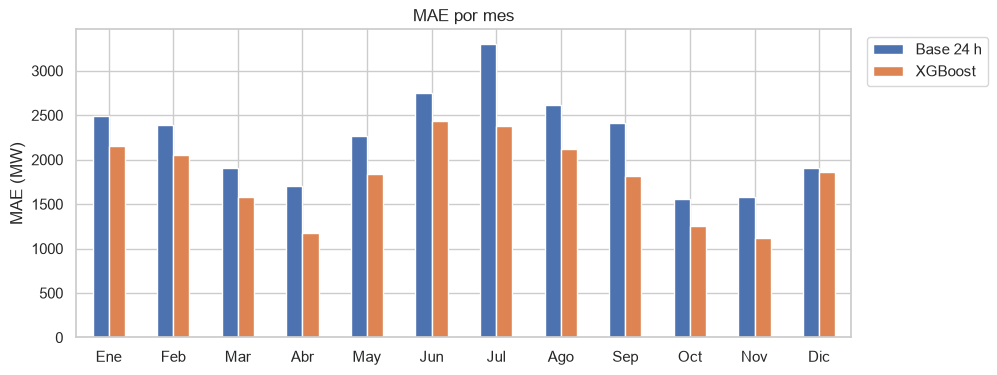

In [11]:
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

mae_mes = resultados.groupby('mes')[['error_base_24h', 'error_xgboost']].mean()
mae_mes.index = [MESES[m - 1] for m in mae_mes.index]
mae_mes.columns = ['Base 24 h', 'XGBoost']

ax = mae_mes.plot.bar(figsize=(10, 4), title='MAE por mes', rot=0)
ax.set_ylabel('MAE (MW)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### 7.3 Por tipo de día

In [12]:
resultados['tipo_dia'] = np.select(
    [resultados['es_festivo'], resultados['es_fin_de_semana']],
    ['Festivo', 'Fin de semana'],
    default='Laborable',
)

(resultados.groupby('tipo_dia')[['error_base_24h', 'error_xgboost']].mean()
 .rename(columns={'error_base_24h': 'MAE Base 24 h', 'error_xgboost': 'MAE XGBoost'})
 .join(resultados['tipo_dia'].value_counts().rename('horas'))
 .round(1))

,MAE Base 24 h,MAE XGBoost,horas
tipo_dia,,,
Festivo,2708.8,1872.4,408
Fin de semana,2556.7,1909.0,3912
Laborable,2177.8,1842.8,9577


### 7.4 Los 10 días con mayor error

Solo se consideran días completos (24 horas): el último día de la serie puede tener pocas horas y su error no es comparable.

In [13]:
resultados['fecha'] = resultados['Datetime'].dt.date

por_dia = (resultados.groupby('fecha')
           .agg(MAE_xgboost=('error_xgboost', 'mean'),
                MAE_base_24h=('error_base_24h', 'mean'),
                festivo=('es_festivo', 'first'),
                horas=('MW', 'size')))

peores = por_dia[por_dia['horas'] == 24].nlargest(10, 'MAE_xgboost').drop(columns='horas')
peores.round(1)

,MAE_xgboost,MAE_base_24h,festivo
fecha,,,
2017-05-20,7776.6,11804.0,False
2018-06-03,6614.6,7221.8,False
2018-07-07,6328.3,10218.8,False
2017-07-29,5498.8,6634.8,False
2018-01-11,5171.9,3488.7,False
2017-03-15,5127.2,3518.2,False
2017-01-11,4921.9,6336.6,False
2018-01-05,4889.6,3132.8,False
2017-09-28,4853.6,5367.5,False


### 7.5 Importancia de las variables

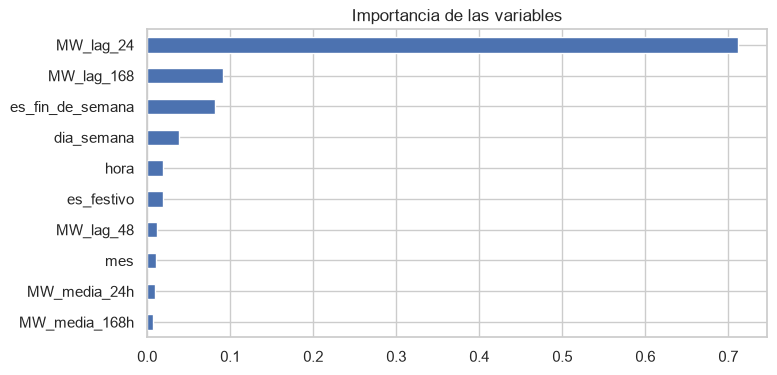

,importancia
MW_lag_24,0.711
MW_lag_168,0.091
es_fin_de_semana,0.081
dia_semana,0.039
hora,0.020
es_festivo,0.019
MW_lag_48,0.012
mes,0.011
MW_media_24h,0.009
MW_media_168h,0.007


In [14]:
importancia = importancia_variables(modelo, list(X_train.columns))

importancia.sort_values('importancia').plot.barh(figsize=(8, 4), legend=False, title='Importancia de las variables')
plt.show()

importancia.round(3)

## 8. Resumen y limitaciones

> Los campos `[completar]` se rellenan con los resultados de las secciones 6 y 7 al ejecutar el notebook con los datos reales.

### Diseño aplicado

| Elemento | Valor |
|---|---|
| Región | `PJME` |
| Horizonte | 24 horas |
| Entrenamiento | `[completar]` |
| Prueba | `[completar]` |
| Variables | Calendario (hora, día de la semana, mes, fin de semana, festivo), rezagos de 24, 48 y 168 h y medias móviles de 24 y 168 h |
| Modelo base | Consumo de hace 24 horas |
| Algoritmo | XGBoost (500 árboles, tasa de aprendizaje 0.05, profundidad 6, `SEMILLA = 42`) |

### Resultados

| Modelo | MAE (MW) | RMSE (MW) | MAPE (%) |
|---|---|---|---|
| Base 24 h | `[completar]` | `[completar]` | `[completar]` |
| Base 168 h | `[completar]` | `[completar]` | `[completar]` |
| XGBoost | `[completar]` | `[completar]` | `[completar]` |

**Interpretación:** `[completar]`

### Limitaciones

- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye. Las variables de calendario y el historial de consumo no pueden anticipar olas de calor o frío, por lo que los picos extremos son los más difíciles de pronosticar.
- **Una sola partición temporal.** Los resultados dependen del periodo elegido para la prueba. Repetir con otros cortes daría una idea de su estabilidad.
- **Una región.** El modelo se entrenó con `PJME`; para otras regiones hay que repetir el proceso.
- **Festivos federales.** Los festivos usados son los federales de EE. UU.; los de cada estado no están incluidos.
- **Parámetros por defecto.** XGBoost no se ha ajustado con búsqueda de hiperparámetros.

**Siguiente paso:** visualización final con los resultados del análisis y del modelo.